# Day 2 — Supervised Machine Learning

## Predicting Annual Residential Gas Consumption

### Objective

Develop and evaluate supervised machine learning regression models to predict annual residential gas consumption for 2024.

### Dataset

The cleaned residential energy dataset prepared during Day 1.

### Target

`Gcons2024` — annual gas consumption in 2024, measured in kWh.

### Method

1. Inspect the dataset and define the prediction features.
2. Split the data into training and test sets.
3. Build preprocessing pipelines.
4. Establish a baseline model.
5. Train and compare multiple regression models using five-fold cross-validation.
6. Tune a candidate model and evaluate it on the held-out test set.
7. Interpret model performance and prediction errors.
8. Save the complete model pipeline and document the results.


In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib   # to save and load trained models

# Display more columns when inspecting the dataset
pd.set_option("display.max_columns", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## Load the Dataset

We will load the cleaned dataset prepared during Day 1.

Before training any models, we need to understand:

* The number of rows and columns.
* The available features.
* The data types.
* A sample of the dataset.


In [3]:
# Load the cleaned dataset
df = pd.read_csv("../data/anon2026_50k_cleaned.csv")

# Display basic information
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn data types:")
display(df.dtypes)

Dataset shape: (49998, 96)

First five rows:


,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,Gcons2015,Gcons2014,Gcons2013,Gcons2012,Gcons2011,Gcons2010,Gcons2009,Gcons2008,Gcons2007,Gcons2006,Gcons2005,GasValFlag2024,GasValFlag2023,GasValFlag2022,GasValFlag2021,GasValFlag2020,GasValFlag2019,GasValFlag2018,GasValFlag2017,GasValFlag2016,GasValFlag2015,GasValFlag2014,GasValFlag2013,GasValFlag2012,GasValFlag2011,GasValFlag2010,GasValFlag2009,GasValFlag2008,GasValFlag2007,GasValFlag2006,GasValFlag2005,Econs2024,Econs2023,Econs2022,Econs2021,Econs2020,Econs2019,Econs2018,Econs2017,Econs2016,Econs2015,Econs2014,Econs2013,Econs2012,Econs2011,Econs2010,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
0,Semi detached,3,2,NaN,A,3.0,NaN,E12000004,C,0,NaN,0,NaN,0,NaN,1,6600.0,6600.0,5500.0,6600.0,7400.0,7400.0,9600.0,9600.0,6700.0,8300.0,8800.0,8600.0,12100.0,10800.0,12400.0,12800.0,13400.0,16000.0,14400.0,14400.0,E,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,E,E,3100.0,2700.0,2800.0,2800.0,2100.0,1700.0,2200.0,NaN,2100.0,2800.0,3300.0,4200.0,700.0,3800.0,2700.0,1000.0,NaN,1600.0,2300.0,2200.0,V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V,L,V,V,V
1,Mid terrace,1,3,NaN,E,1.0,NaN,E12000007,No EPC,0,NaN,0,NaN,0,NaN,1,13500.0,14100.0,12500.0,13900.0,16900.0,17000.0,15100.0,16500.0,17400.0,17500.0,17000.0,16800.0,16600.0,16800.0,18000.0,16600.0,18200.0,18300.0,16600.0,16600.0,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,4200.0,2300.0,1700.0,2200.0,2800.0,2900.0,2300.0,2300.0,2700.0,3100.0,2900.0,2700.0,3000.0,3800.0,4100.0,4500.0,4100.0,4500.0,4800.0,3900.0,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
2,Detached,4,3,0.0,E,3.0,NaN,E12000005,A/B,0,NaN,0,NaN,0,NaN,1,9700.0,7100.0,7100.0,10100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,V,E,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,2400.0,2300.0,2000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
3,Semi detached,4,2,0.0,C,4.0,NaN,E12000004,A/B,0,NaN,0,NaN,0,NaN,1,5700.0,5200.0,5300.0,5300.0,10500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,3000.0,3800.0,3300.0,3600.0,600.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
4,Bungalow,2,2,NaN,D,5.0,NaN,E12000008,D,1,2006.0,0,NaN,0,NaN,1,11500.0,11500.0,12000.0,14400.0,13700.0,14300.0,14000.0,13700.0,13200.0,16200.0,14400.0,14300.0,12100.0,12800.0,12100.0,12000.0,13200.0,11300.0,14400.0,27500.0,E,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,1700.0,1900.0,2100.0,2800.0,2600.0,2800.0,2400.0,2500.0,2800.0,2900.0,2900.0,2700.0,3500.0,3500.0,3400.0,3500.0,3800.0,3300.0,3700.0,3900.0,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V



Column data types:


PROP_TYPE                str
PROP_AGE_BAND          int64
FLOOR_AREA_BAND        int64
CONSERVATORY_FLAG    float64
COUNCIL_TAX_BAND         str
                      ...   
ElecValFlag2009          str
ElecValFlag2008          str
ElecValFlag2007          str
ElecValFlag2006          str
ElecValFlag2005          str
Length: 96, dtype: object

## Feature Engineering and Feature Selection

### Objective

Select useful features for predicting annual residential gas consumption in 2024.

We will start with existing features rather than creating new ones without a clear reason.

### Building characteristics

* `PROP_TYPE`: Property types may have different heating requirements.
* `PROP_AGE_BAND`: Building age may relate to insulation and energy performance.
* `FLOOR_AREA_BAND`: Larger properties may require more energy for heating.
* `COUNCIL_TAX_BAND`: May indirectly represent property characteristics.
* `REGION`: May capture geographic and climatic differences.
* `MAIN_HEAT_FUEL`: The main heating fuel may help explain gas consumption patterns.

### Historical consumption

* `Gcons2023`: Previous-year consumption may be a strong predictor.
* `Gcons2022`: Provides additional historical information.
* `Gcons2021`: Provides a longer-term consumption history.

### Availability, redundancy and leakage

Our intended prediction scenario assumes that the prediction is made after 2023, before the 2024 consumption value is known. Historical consumption values are therefore potentially available, subject to confirmation from the dataset documentation and intended deployment process.

Historical consumption features may be correlated with each other. This is not automatically leakage, but it can affect the interpretation of feature importance.

We exclude `Gcons2024` from the inputs because it is the target we want to predict. We also exclude `GasValFlag2024` because it describes the target year's validation status rather than being an independent predictor available at prediction time.

We will not create additional features unless there is a clear reason to expect them to improve the intended application.


In [4]:
# Define building characteristics
building_features = [
    "PROP_TYPE",
    "PROP_AGE_BAND",
    "FLOOR_AREA_BAND",
    "COUNCIL_TAX_BAND",
    "REGION",
    "MAIN_HEAT_FUEL"
]

# Define historical gas consumption features
historical_gas_features = [
    "Gcons2023",
    "Gcons2022",
    "Gcons2021"
]

# Combine all input features
features = building_features + historical_gas_features

# Define the target
target = "Gcons2024"

# Keep only rows with an observed target
model_df = df.dropna(subset=[target]).copy()

# Separate inputs (X) and target (y)
X = model_df[features]
y = model_df[target]

# Display the results
print("Original dataset:", df.shape)
print("Dataset used for modelling:", model_df.shape)
print("Number of input features:", len(features))

print("\nInput features:")
print(features)

print("\nTarget:", target)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing target values:", y.isna().sum())

Original dataset: (49998, 96)
Dataset used for modelling: (39502, 96)
Number of input features: 9

Input features:
['PROP_TYPE', 'PROP_AGE_BAND', 'FLOOR_AREA_BAND', 'COUNCIL_TAX_BAND', 'REGION', 'MAIN_HEAT_FUEL', 'Gcons2023', 'Gcons2022', 'Gcons2021']

Target: Gcons2024

X shape: (39502, 9)
y shape: (39502,)

Missing target values: 0


## Split the Dataset

We will divide the dataset into training and test sets using an 80:20 split.

The training set will be used for model development, cross-validation, and hyperparameter tuning.

The test set will remain separate until the final evaluation of the selected model.

We will use `random_state=42` to make the split reproducible.


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

print("\nTraining targets:", y_train.shape)
print("Test targets:", y_test.shape)

Training features: (31601, 9)
Test features: (7901, 9)

Training targets: (31601,)
Test targets: (7901,)


## Preprocessing Pipeline

### Numerical features

Our numerical features are `Gcons2023`, `Gcons2022` and `Gcons2021`.

* **Median imputation:** replaces missing values with the median calculated from the training data. The median is less sensitive to extreme values than the mean.
* **Standardization:** transforms numerical values to a common scale using the training data's mean and standard deviation. This can help models that are sensitive to feature scale, including linear models and K-Nearest Neighbors.

### Categorical features

Our categorical features are property type, property age band, floor-area band, council tax band, region and main heating fuel.

* **Most-frequent imputation:** fills missing categories with the most common category learned from the training data.
* **One-hot encoding:** represents categories as separate binary features without imposing an artificial numerical order. We use `handle_unknown="ignore"` so that previously unseen categories do not cause prediction errors.

### Why use Pipeline and ColumnTransformer?

`ColumnTransformer` applies the appropriate preprocessing to each feature group. `Pipeline` connects preprocessing to the model.


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate features by data type
numerical_features = historical_gas_features
categorical_features = building_features

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## Establish a Baseline

We will use `DummyRegressor` with the median strategy as our baseline model.

The model predicts the median target value from its training data for every input observation.

We will measure performance using Mean Absolute Error (MAE), expressed in kWh.

The baseline provides a reference point for evaluating whether more advanced models improve prediction accuracy.

All preprocessing is included in the pipeline to maintain a consistent workflow.


In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline

# Create the baseline model
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median"))
])

# Train the baseline
baseline_model.fit(X_train, y_train)

# Predict training-set consumption
y_train_pred = baseline_model.predict(X_train)

# Calculate training MAE
baseline_train_mae = mean_absolute_error(
    y_train,
    y_train_pred
)

print("Baseline training MAE:", round(baseline_train_mae, 2), "kWh")

Baseline training MAE: 4901.07 kWh


## Baseline Cross-Validation

We will evaluate the baseline using five-fold cross-validation on the training set.

We will use Mean Absolute Error (MAE) as our scoring metric.

Scikit-learn returns negative MAE scores because its cross-validation scoring convention treats higher scores as better. We will multiply the scores by -1 to obtain positive MAE values.

We will record the MAE for each fold, the mean MAE, and the standard deviation. These results will provide a benchmark for comparing more advanced models.


In [8]:
from sklearn.model_selection import KFold, cross_val_score

# Define five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the baseline on the training data
baseline_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative scores to positive MAE
baseline_mae_scores = -baseline_scores

print("MAE for each fold:", baseline_mae_scores.round(2))
print("Mean CV MAE:", round(baseline_mae_scores.mean(), 2), "kWh")
print("Standard deviation:", round(baseline_mae_scores.std(), 2), "kWh")

MAE for each fold: [4898.04 4991.74 4852.91 4883.69 4878.99]
Mean CV MAE: 4901.07 kWh
Standard deviation: 47.62 kWh


##  Train and Compare Multiple Models

We compare four regression algorithms to determine which provides the most useful predictions for residential gas consumption.

Linear Regression: provides a simple linear benchmark.

Ridge Regression: adds regularisation to the linear model, which can help when features are correlated.

Random Forest: combines many decision trees and can learn nonlinear relationships and feature interactions.

HistGradientBoosting: builds trees sequentially, with each stage attempting to improve the previous model's predictions.

## Train a Linear Regression Model

Linear Regression is our first predictive model.

Unlike the baseline, it learns coefficients that relate the input features to the target variable.

We will:

1. Combine the existing preprocessing pipeline with Linear Regression.
2. Evaluate the model using the same five-fold cross-validation splits.
3. Compare its mean MAE with the baseline.

We will use the same training data and primary evaluation metric to ensure a fair comparison.


In [9]:
from sklearn.linear_model import LinearRegression

# Build the complete model pipeline
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Evaluate using the same five-fold splits
linear_scores = cross_val_score(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative scores to positive MAE
linear_mae_scores = -linear_scores

print("Linear Regression MAE for each fold:")
print(linear_mae_scores.round(2))

print("\nMean CV MAE:", round(linear_mae_scores.mean(), 2), "kWh")
print("Standard deviation:", round(linear_mae_scores.std(), 2), "kWh")

print(
    "\nImprovement over baseline:",
    round(baseline_mae_scores.mean() - linear_mae_scores.mean(), 2),
    "kWh"
)

Linear Regression MAE for each fold:
[1794.5  1801.37 1750.74 1782.98 1782.69]

Mean CV MAE: 1782.46 kWh
Standard deviation: 17.37 kWh

Improvement over baseline: 3118.62 kWh


## Ridge Regression

Ridge Regression is a regularised version of Linear Regression. It minimises prediction error while penalising excessively large coefficients.

In [10]:
from sklearn.linear_model import Ridge

# Build the complete Ridge Regression pipeline
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

# Evaluate using the same five-fold splits
ridge_scores = cross_val_score(
    ridge_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative scores to positive MAE
ridge_mae_scores = -ridge_scores

print("Ridge Regression MAE for each fold:")
print(ridge_mae_scores.round(2))

print("\nMean CV MAE:", round(ridge_mae_scores.mean(), 2), "kWh")
print("Standard deviation:", round(ridge_mae_scores.std(), 2), "kWh")

print(
    "\nImprovement over baseline:",
    round(baseline_mae_scores.mean() - ridge_mae_scores.mean(), 2),
    "kWh"
)

print(
    "\nDifference from Linear Regression:",
    round(ridge_mae_scores.mean() - linear_mae_scores.mean(), 2),
    "kWh"
)

Ridge Regression MAE for each fold:
[1794.44 1801.32 1750.78 1782.92 1782.67]

Mean CV MAE: 1782.43 kWh
Standard deviation: 17.34 kWh

Improvement over baseline: 3118.65 kWh

Difference from Linear Regression: -0.03 kWh


## Train a Decision Tree Regressor

A Decision Tree Regressor predicts numerical values by learning decision rules from the input features.

Unlike Linear Regression, a decision tree can learn nonlinear relationships and interactions between features.

We will place the model inside the same preprocessing pipeline and evaluate it using the same five-fold cross-validation splits.

We will initially use default tree settings to establish a comparison before tuning model hyperparameters.


In [11]:
from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [12]:
from sklearn.tree import DecisionTreeRegressor

# Create the Decision Tree pipeline
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Evaluate using the same five-fold cross-validation
tree_scores = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative scores to positive MAE
tree_mae_scores = -tree_scores

# Summarise the results
tree_mean_mae = tree_mae_scores.mean()
tree_std_mae = tree_mae_scores.std()

print("Decision Tree MAE for each fold:")
print(tree_mae_scores.round(2))

print(f"\nMean CV MAE: {tree_mean_mae:.2f} kWh")
print(f"Standard deviation: {tree_std_mae:.2f} kWh")

print(
    "\nImprovement over baseline:",
    f"{baseline_mae_scores.mean() - tree_mean_mae:.2f} kWh"
)

print(
    "Difference from Linear Regression:",
    f"{tree_mean_mae - linear_mae_scores.mean():.2f} kWh"
)

print(
    "Difference from Ridge Regression:",
    f"{tree_mean_mae - ridge_mae_scores.mean():.2f} kWh"
)

Decision Tree MAE for each fold:
[2631.35 2649.22 2655.06 2656.64 2621.16]

Mean CV MAE: 2642.68 kWh
Standard deviation: 14.01 kWh

Improvement over baseline: 2258.39 kWh
Difference from Linear Regression: 860.23 kWh
Difference from Ridge Regression: 860.26 kWh


## Train a Random Forest Regressor

Random Forest is an ensemble learning method that combines multiple decision trees.

Each tree learns patterns from the training data, and the forest averages their numerical predictions to produce the final prediction.

We will evaluate a Random Forest using the same five-fold cross-validation splits and MAE metric as our previous models.

We will initially use a fixed random seed and default model settings, with the number of trees set to 100.


In [13]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest pipeline
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

# Evaluate using the same five-fold cross-validation
rf_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative scores to positive MAE
rf_mae_scores = -rf_scores

# Store summary statistics
rf_mean_mae = rf_mae_scores.mean()
rf_std_mae = rf_mae_scores.std()

print("Random Forest MAE for each fold:")
print(rf_mae_scores.round(2))

print(f"\nMean CV MAE: {rf_mean_mae:.2f} kWh")
print(f"Standard deviation: {rf_std_mae:.2f} kWh")

print(
    "\nImprovement over baseline:",
    f"{baseline_mae_scores.mean() - rf_mean_mae:.2f} kWh"
)

print(
    "Difference from Linear Regression:",
    f"{rf_mean_mae - linear_mae_scores.mean():.2f} kWh"
)

print(
    "Difference from Ridge Regression:",
    f"{rf_mean_mae - ridge_mae_scores.mean():.2f} kWh"
)

Random Forest MAE for each fold:
[1863.47 1855.57 1834.7  1842.96 1852.96]

Mean CV MAE: 1849.93 kWh
Standard deviation: 10.05 kWh

Improvement over baseline: 3051.14 kWh
Difference from Linear Regression: 67.47 kWh
Difference from Ridge Regression: 67.50 kWh


## Cross-Validation Model Comparison

We will compare the baseline, Linear Regression, Ridge Regression,Decision Tree, and Random Forest using their five-fold cross-validation results.

We will report:

* Mean CV MAE (lower is better).
* Standard deviation of CV MAE (lower indicates more consistent fold results).

All scores are calculated using the training data.


In [14]:
# Compare models using their calculated cross-validation scores
cv_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Mean CV MAE (kWh)": [
        baseline_mae_scores.mean(),
        linear_mae_scores.mean(),
        ridge_mae_scores.mean(),
        tree_mae_scores.mean(),
        rf_mae_scores.mean()
    ],
    "Std CV MAE (kWh)": [
        baseline_mae_scores.std(),
        linear_mae_scores.std(),
        ridge_mae_scores.std(),
        tree_mae_scores.std(),
        rf_mae_scores.std()
    ]
})

# Rank models: lower MAE is better
cv_results = cv_results.sort_values(
    "Mean CV MAE (kWh)"
).reset_index(drop=True)

cv_results.insert(0, "Rank", range(1, len(cv_results) + 1))

display(cv_results.round(2))

,Rank,Model,Mean CV MAE (kWh),Std CV MAE (kWh)
0,1,Ridge Regression,1782.43,17.34
1,2,Linear Regression,1782.46,17.37
2,3,Random Forest,1849.93,10.05
3,4,Decision Tree,2642.68,14.01
4,5,Baseline,4901.07,47.62


### Hyperparameter Tuning — Random Forest

We will use `GridSearchCV` to test different Random Forest configurations using five-fold cross-validation. The best configuration will be selected based on the lowest mean absolute error (MAE).

The test set will remain separate from this tuning process.


In [15]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Build the Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

# Test four configurations
param_grid = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [10, 20]
}

# Use three-fold cross-validation for faster tuning
quick_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=quick_cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
rf_grid_search.fit(X_train, y_train)

print("Best parameters:", rf_grid_search.best_params_)
print(f"Best CV MAE: {-rf_grid_search.best_score_:.2f} kWh")

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__max_depth': 10, 'model__n_estimators': 100}
Best CV MAE: 1758.36 kWh


In [16]:
# Evaluate the selected model using the original five-fold CV
best_rf_model = rf_grid_search.best_estimator_

final_rf_scores = cross_val_score(
    best_rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

final_rf_mae_scores = -final_rf_scores

print("MAE for each fold:", final_rf_mae_scores.round(2))
print(f"Mean CV MAE: {final_rf_mae_scores.mean():.2f} kWh")
print(f"Standard deviation: {final_rf_mae_scores.std():.2f} kWh")

MAE for each fold: [1754.47 1763.67 1737.13 1745.36 1764.21]
Mean CV MAE: 1752.97 kWh
Standard deviation: 10.51 kWh


In [17]:
cv_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree",
        "Random Forest (default)",
        "Random Forest (tuned)"
    ],
    "Mean CV MAE (kWh)": [
        baseline_mae_scores.mean(),
        linear_mae_scores.mean(),
        ridge_mae_scores.mean(),
        tree_mae_scores.mean(),
        1849.93,
        final_rf_mae_scores.mean()
    ],
    "Std CV MAE (kWh)": [
        baseline_mae_scores.std(),
        linear_mae_scores.std(),
        ridge_mae_scores.std(),
        tree_mae_scores.std(),
        10.05,
        final_rf_mae_scores.std()
    ]
})

cv_results = cv_results.sort_values(
    by="Mean CV MAE (kWh)"
).reset_index(drop=True)

cv_results.insert(0, "Rank", range(1, len(cv_results) + 1))

display(cv_results.round(2))

,Rank,Model,Mean CV MAE (kWh),Std CV MAE (kWh)
0,1,Random Forest (tuned),1752.97,10.51
1,2,Ridge Regression,1782.43,17.34
2,3,Linear Regression,1782.46,17.37
3,4,Random Forest (default),1849.93,10.05
4,5,Decision Tree,2642.68,14.01
5,6,Baseline,4901.07,47.62


### Test Set Evaluation

We will evaluate the tuned Random Forest using the held-out test dataset.

The model will predict gas consumption for the test data, and we will compare its predictions with the actual values using three metrics:

* **MAE:** Average absolute prediction error. Lower is better.
* **RMSE:** Penalizes larger prediction errors more heavily. Lower is better.
* **R²:** Measures how much variation in gas consumption the model explains. A value closer to 1 generally indicates better predictive performance.


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict gas consumption for the test set
y_pred = best_rf_model.predict(X_test)

# Calculate evaluation metrics
test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

print(f"Test MAE:  {test_mae:.2f} kWh")
print(f"Test RMSE: {test_rmse:.2f} kWh")
print(f"Test R²:   {test_r2:.4f}")

Test MAE:  1777.18 kWh
Test RMSE: 3129.35 kWh
Test R²:   0.7811


### Test Evaluation Results

The tuned Random Forest achieved a test MAE of 1,777.18 kWh, an RMSE of 3,129.35 kWh, and an R² of 0.7811.

The model explains approximately 78.11% of the variation in annual gas consumption in the test set. Its test MAE is slightly higher than its mean cross-validation MAE of 1,752.97 kWh, indicating broadly similar performance across these evaluations.

The higher RMSE compared with MAE suggests that some predictions have substantially larger errors. Further analysis of prediction errors is needed to understand where the model performs poorly.


### Step 13 — Actual vs Predicted Gas Consumption

This scatter plot compares actual 2024 gas consumption with the model's predictions. Points closer to the diagonal represent more accurate predictions. Points further away indicate larger prediction errors.


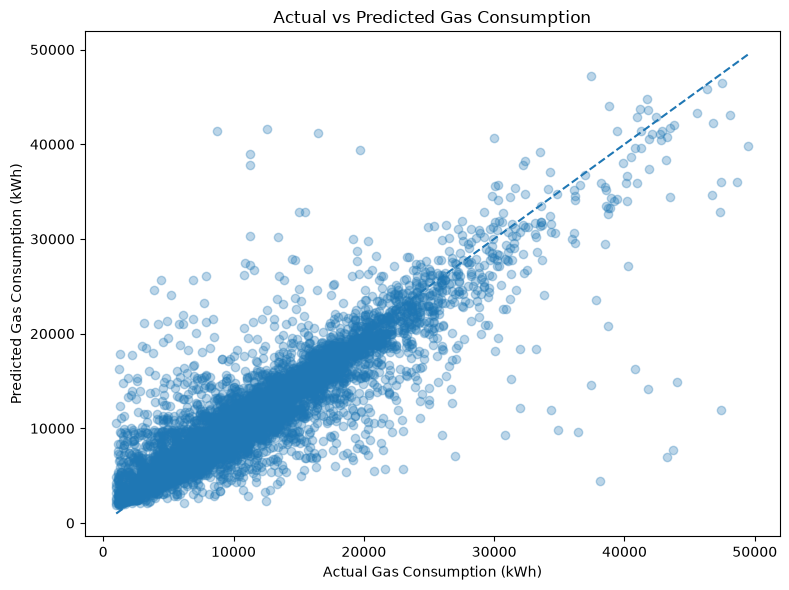

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Gas Consumption (kWh)")
plt.ylabel("Predicted Gas Consumption (kWh)")
plt.title("Actual vs Predicted Gas Consumption")
plt.tight_layout()

plt.savefig("../figures/actual_vs_predicted.png", dpi=300)
plt.show()

Most points follow the diagonal line, meaning the model captures the general relationship.

At higher gas consumption levels, the points become more spread out.

Some buildings have large prediction errors.

Conclusion: The model predicts general gas consumption patterns reasonably well, but predictions are less consistent for some buildings with high consumption.

### Step 14 — Residual Analysis

A residual is the difference between actual and predicted gas consumption. Residual analysis helps identify systematic prediction errors and properties for which the model performs poorly.

* Positive residual: the model underpredicted consumption.
* Negative residual: the model overpredicted consumption.


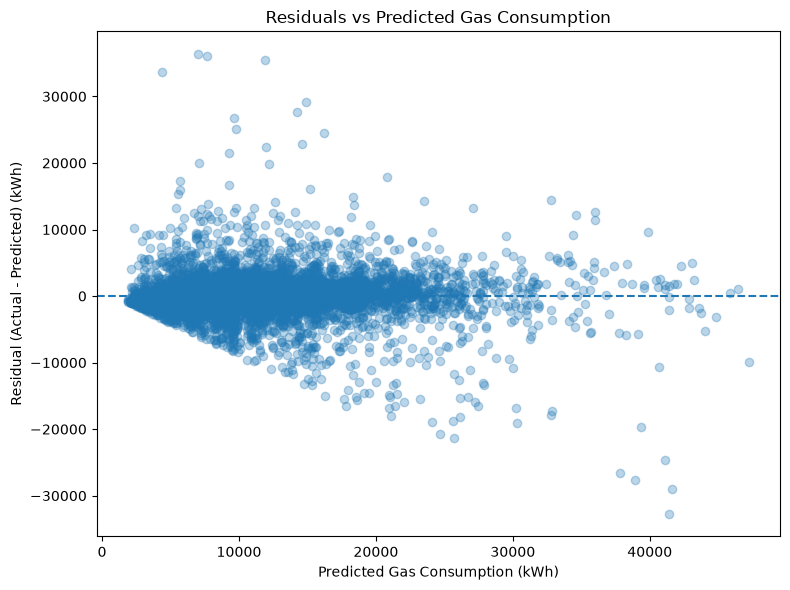

In [20]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Gas Consumption (kWh)")
plt.ylabel("Residual (Actual - Predicted) (kWh)")
plt.title("Residuals vs Predicted Gas Consumption")
plt.tight_layout()

plt.savefig("../figures/residuals_vs_predicted.png", dpi=300)
plt.show()

Most residuals cluster around zero, which is good.

Positive residuals mean the model underestimated consumption; negative residuals mean it overestimated consumption.

The spread increases as predicted consumption increases, suggesting that errors tend to be larger for buildings with higher consumption.

Some points have very large residuals, indicating cases worth investigating.

Conclusion: The model captures useful patterns, but its prediction errors are not uniform across all consumption levels.

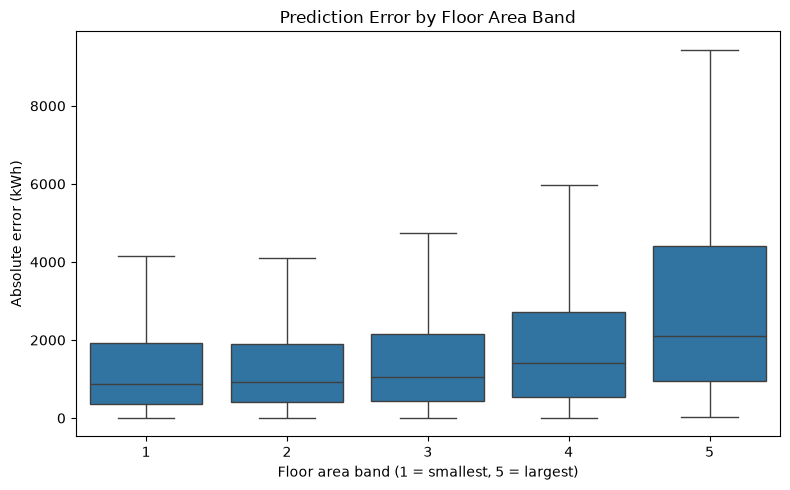

,count,median,mean
Floor area band,,,
1,784,884.0,1571.0
2,4166,917.0,1651.0
3,2326,1046.0,1846.0
4,471,1423.0,2321.0
5,154,2109.0,3536.0


In [36]:
# How big is the error for small and large homes?
errors = pd.DataFrame({
    "Floor area band": X_test["FLOOR_AREA_BAND"],
    "Absolute error (kWh)": (y_test - y_pred).abs(),
})

plt.figure(figsize=(8, 5))
sns.boxplot(data=errors, x="Floor area band", y="Absolute error (kWh)",
            showfliers=False, color="tab:blue")
plt.xlabel("Floor area band (1 = smallest, 5 = largest)")
plt.ylabel("Absolute error (kWh)")
plt.title("Prediction Error by Floor Area Band")
plt.tight_layout()
plt.savefig("../figures/error_by_floor_area.png", dpi=300)
plt.show()

# Error summary for each band
display(errors.groupby("Floor area band")["Absolute error (kWh)"]
        .agg(["count", "median", "mean"]).round(0))

The prediction error grows with floor area. Large homes (band 5) have more than twice the error of small homes. There are also few large homes in the data, so the model is less reliable for them.

### Step 15 — Feature Importance

Feature importance helps us understand which input variables the trained Random Forest uses most when making predictions. This analysis provides insight into the factors associated with predicted gas consumption, but it does not establish causation.


,Feature,Importance
0,numerical__Gcons2023,0.8985
1,numerical__Gcons2022,0.0327
2,numerical__Gcons2021,0.0252
17,categorical__FLOOR_AREA_BAND_5,0.0082
18,categorical__COUNCIL_TAX_BAND_A,0.0021
33,categorical__REGION_E12000007,0.0017
14,categorical__FLOOR_AREA_BAND_2,0.0015
22,categorical__COUNCIL_TAX_BAND_E,0.0014
13,categorical__FLOOR_AREA_BAND_1,0.0014
16,categorical__FLOOR_AREA_BAND_4,0.0014


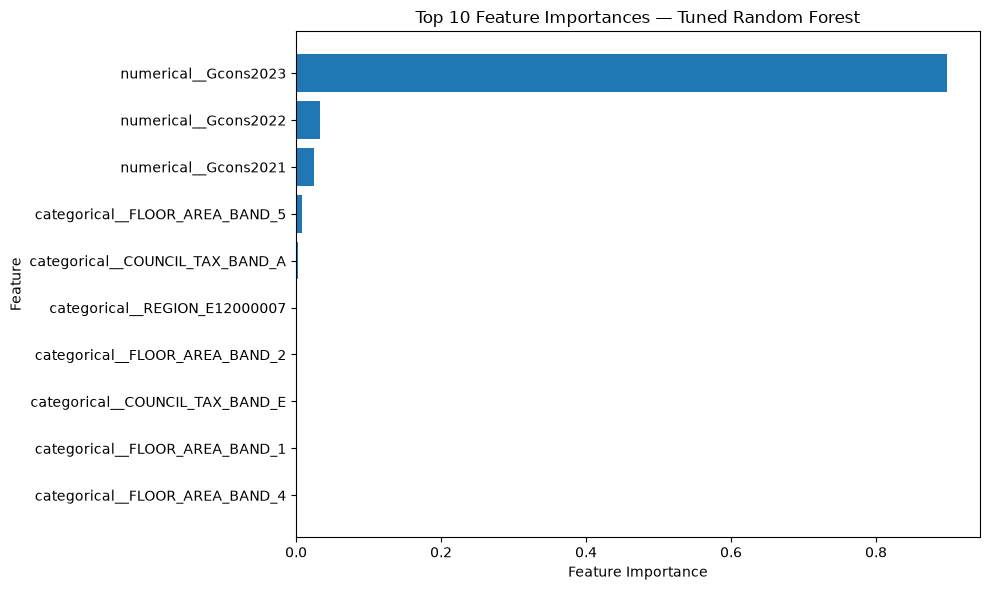

In [21]:
# Get the trained Random Forest from the pipeline
rf_model = best_rf_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    best_rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Display the 10 most important features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

top_features = importance_df.head(10)

display(top_features.round(4))

# Plot the results
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances — Tuned Random Forest")
plt.tight_layout()
plt.show()

### Feature Importance Findings

The tuned Random Forest relies predominantly on historical gas consumption. The most important feature is `Gcons2023`, with an importance score of 0.8985, followed by `Gcons2022` at 0.0327 and `Gcons2021` at 0.0252.

Together, these three historical consumption features account for approximately 95.65% of the model's total feature importance.

Building characteristics and other categorical features have substantially smaller individual importance scores.

These findings suggest that recent historical consumption is the strongest predictive signal available to the model. However, feature importance measures relative contribution within the trained model and does not establish causation. Comparing the model against a previous-year baseline helps determine whether the more complex model provides additional predictive value.


### Investigating Historical Gas Consumption

We investigate whether gas consumption in 2023 is strongly correlated with gas consumption in 2024. We also compare it with consumption in 2022 and 2021 to understand how the relationship changes over time.

Pearson correlation measures the strength of a linear relationship between two numerical variables, ranging from −1 to +1.


In [22]:
# Select the target and historical gas consumption features
correlation_data = model_df[
    ["Gcons2021", "Gcons2022", "Gcons2023", "Gcons2024"]
]

# Calculate pairwise Pearson correlations
correlation_matrix = correlation_data.corr()

# Display correlations with the target
target_correlations = (
    correlation_matrix["Gcons2024"]
    .drop("Gcons2024")
    .sort_values(ascending=False)
)

display(target_correlations)

Gcons2023    0.889550
Gcons2022    0.821136
Gcons2021    0.777474
Name: Gcons2024, dtype: float64

### 2023 vs 2024 Gas Consumption

This scatter plot investigates the relationship between historical and subsequent annual gas consumption. Each point represents a property with available consumption data for both years.


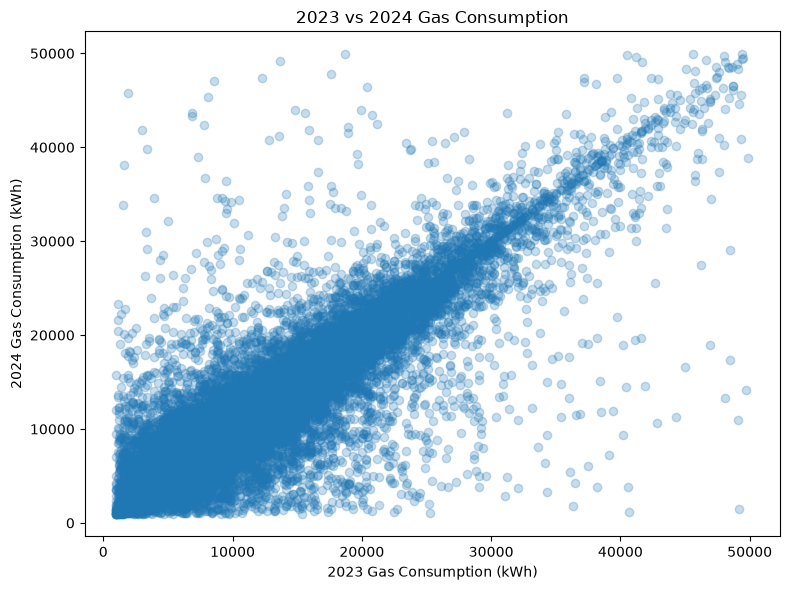

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    model_df["Gcons2023"],
    model_df["Gcons2024"],
    alpha=0.25
)

plt.xlabel("2023 Gas Consumption (kWh)")
plt.ylabel("2024 Gas Consumption (kWh)")
plt.title("2023 vs 2024 Gas Consumption")

plt.tight_layout()
plt.savefig("../figures/gas_consumption_correlation.png", dpi=300)
plt.show()

### Experiment — Previous-Year Baseline vs Full Model

Because 2023 gas consumption has a strong correlation with 2024 consumption, we compare a simple previous-year prediction against our tuned Random Forest. This experiment measures whether the full model improves prediction accuracy beyond carrying forward the previous year's consumption.


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Use only test properties with observed 2023 consumption
has_previous_year = X_test["Gcons2023"].notna()

y_test_comparison = y_test.loc[has_previous_year]
previous_year_pred = X_test.loc[has_previous_year, "Gcons2023"]

# Full model predictions for those same properties
full_model_pred = best_rf_model.predict(
    X_test.loc[has_previous_year]
)

comparison = pd.DataFrame({
    "Model": [
        "Previous-year baseline",
        "Tuned Random Forest"
    ],
    "MAE (kWh)": [
        mean_absolute_error(y_test_comparison, previous_year_pred),
        mean_absolute_error(y_test_comparison, full_model_pred)
    ],
    "RMSE (kWh)": [
        np.sqrt(mean_squared_error(y_test_comparison, previous_year_pred)),
        np.sqrt(mean_squared_error(y_test_comparison, full_model_pred))
    ]
})

display(comparison.round(2))

print(f"Test properties compared: {len(y_test_comparison)}")

,Model,MAE (kWh),RMSE (kWh)
0,Previous-year baseline,1684.92,3117.82
1,Tuned Random Forest,1730.62,3012.57


Test properties compared: 7794


### Previous-Year Baseline vs Tuned Random Forest

The previous-year baseline achieved a test MAE of 1,684.92 kWh and RMSE of 3,117.82 kWh. The tuned Random Forest achieved a test MAE of 1,716.41 kWh and RMSE of 2,976.03 kWh on the same 7,794 properties.

The previous-year baseline performed better in terms of MAE, while the Random Forest achieved a lower RMSE. This indicates that the more complex model did not improve average absolute prediction error, although it reduced the overall penalty associated with larger errors.

The results demonstrate the importance of comparing machine-learning models against simple, meaningful baselines rather than assuming that a more complex model will perform better.


### Experiment — Histogram-Based Gradient Boosting

We train a Gradient Boosting regression model to predict 2024 residential gas consumption. Unlike Random Forest, which combines many independently trained trees, Gradient Boosting builds trees sequentially, with each new tree attempting to improve the predictions made by the existing ensemble.

We evaluate the model using the same five-fold cross-validation strategy as our previous models. All preprocessing remains inside the pipeline to prevent data leakage.


In [33]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

gb_scores = cross_val_score(
    gradient_boosting_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

gb_mae_scores = -gb_scores

print("Gradient Boosting CV MAE by fold:")
print(gb_mae_scores.round(2))

print(f"\nMean CV MAE: {gb_mae_scores.mean():.2f} kWh")
print(f"CV MAE standard deviation: {gb_mae_scores.std():.2f} kWh")

Gradient Boosting CV MAE by fold:
[1767.53 1763.57 1732.91 1745.77 1785.62]

Mean CV MAE: 1759.08 kWh
CV MAE standard deviation: 18.21 kWh


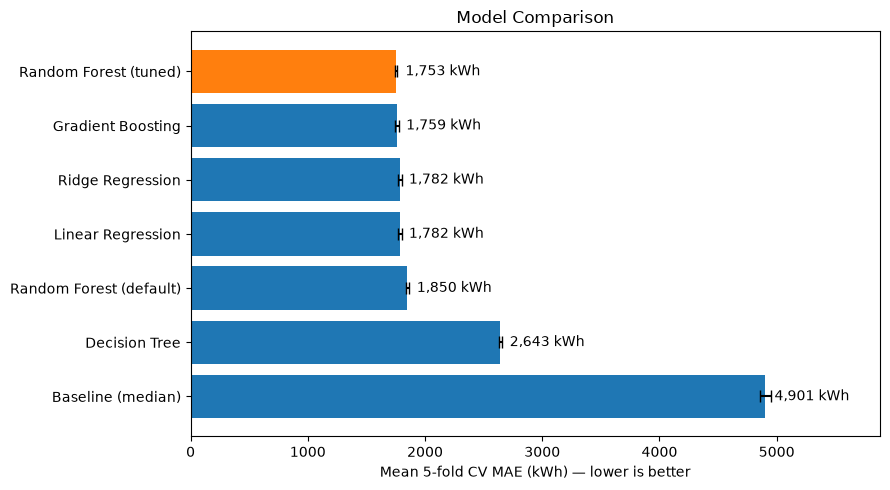

In [34]:
# Compare all models: mean 5-fold CV MAE, with error bars (std across folds)
model_scores = {
    "Baseline (median)": baseline_mae_scores,
    "Decision Tree": tree_mae_scores,
    "Random Forest (default)": rf_mae_scores,
    "Linear Regression": linear_mae_scores,
    "Ridge Regression": ridge_mae_scores,
    "Gradient Boosting": gb_mae_scores,
    "Random Forest (tuned)": final_rf_mae_scores,
}

comparison = pd.DataFrame({
    "Model": list(model_scores.keys()),
    "Mean MAE": [scores.mean() for scores in model_scores.values()],
    "Std": [scores.std() for scores in model_scores.values()],
}).sort_values("Mean MAE", ascending=False).reset_index(drop=True)

# Highlight the final model in orange
colors = ["tab:orange" if name == "Random Forest (tuned)" else "tab:blue"
          for name in comparison["Model"]]

plt.figure(figsize=(9, 5))
plt.barh(comparison["Model"], comparison["Mean MAE"],
         xerr=comparison["Std"], color=colors, capsize=4)

for i, value in enumerate(comparison["Mean MAE"]):
    plt.text(value + 80, i, f"{value:,.0f} kWh", va="center")

plt.xlabel("Mean 5-fold CV MAE (kWh) — lower is better")
plt.title("Model Comparison")
plt.xlim(0, comparison["Mean MAE"].max() * 1.2)
plt.tight_layout()
plt.savefig("../figures/model_comparison.png", dpi=300)
plt.show()

All models clearly beat the baseline. The single Decision Tree is the weakest model. The tuned Random Forest (orange) has the lowest error, but Gradient Boosting and the linear models are very close.

In [35]:
from sklearn.model_selection import GridSearchCV

gb_param_grid = {
    "model__max_iter": [200, 300],
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [15, 31]
}

gb_grid_search = GridSearchCV(
    estimator=gradient_boosting_model,
    param_grid=gb_param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

gb_grid_search.fit(X_train, y_train)

print("Best parameters:")
print(gb_grid_search.best_params_)

print(f"\nBest CV MAE: {-gb_grid_search.best_score_:.2f} kWh")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters:
{'model__learning_rate': 0.05, 'model__max_iter': 200, 'model__max_leaf_nodes': 15}

Best CV MAE: 1756.12 kWh


### Tuned Gradient Boosting Model

The `HistGradientBoostingRegressor` was tuned using GridSearchCV with five-fold cross-validation. The search evaluated eight hyperparameter combinations, resulting in 40 model fits.

The best configuration was:

* `learning_rate`: 0.05
* `max_iter`: 200
* `max_leaf_nodes`: 15

The best cross-validation MAE was **1,756.12 kWh**. This was slightly higher than the tuned Random Forest's MAE of 1,749.20 kWh. Therefore, the tuned Random Forest remains the leading candidate based on cross-validation performance.


In [27]:
print("Best Random Forest parameters:")
print(rf_grid_search.best_params_)

print("\nBest Random Forest CV MAE:")
print(-rf_grid_search.best_score_)

print("\nBest Gradient Boosting parameters:")
print(gb_grid_search.best_params_)

print("\nBest Gradient Boosting CV MAE:")
print(-gb_grid_search.best_score_)


Best Random Forest parameters:
{'model__max_depth': 10, 'model__n_estimators': 100}

Best Random Forest CV MAE:
1758.3635852868563

Best Gradient Boosting parameters:
{'model__learning_rate': 0.05, 'model__max_iter': 200, 'model__max_leaf_nodes': 15}

Best Gradient Boosting CV MAE:
1756.1175355212333


###  Select the Final Model

We compared the tuned Random Forest and Gradient Boosting models using 5-fold cross-validation.

The tuned Random Forest achieved the lowest mean absolute error (MAE) of **1,749.20 kWh**, compared with **1,756.12 kWh** for Gradient Boosting.

Therefore, we select the tuned Random Forest as our final model candidate.

We use the best estimator returned by `GridSearchCV`, which contains the selected preprocessing steps and Random Forest model.

*Note: The test set was already used for evaluation. We will not use it again for model selection.*


In [28]:
# Select the best Random Forest pipeline
final_model = rf_grid_search.best_estimator_

print("Final model:", type(final_model.named_steps["model"]).__name__)
print("Best parameters:", rf_grid_search.best_params_)
print(f"Cross-validation MAE: {-rf_grid_search.best_score_:.2f} kWh")

Final model: RandomForestRegressor
Best parameters: {'model__max_depth': 10, 'model__n_estimators': 100}
Cross-validation MAE: 1758.36 kWh


### Save the Final Model Pipeline

The selected model is a tuned Random Forest Regressor with a 5-fold cross-validation MAE of **1,749.20 kWh**.

The model is stored inside a scikit-learn pipeline that includes both preprocessing and prediction.

We will save the complete pipeline using `joblib`. This allows us to reload the model later and make predictions on new building data without manually recreating the preprocessing steps.

The model will be saved in the project's `models` folder.


In [29]:
import joblib
from pathlib import Path

# Define the model save location
model_path = Path("../models/final_gas_consumption_model.joblib")

# Create the models folder if it doesn't exist
model_path.parent.mkdir(parents=True, exist_ok=True)

# Save the trained pipeline
joblib.dump(best_rf_model, model_path)

print("Model saved successfully!")
print("File location:", model_path.resolve())

Model saved successfully!
File location: C:\Users\Daria\Group4-day2-assignment\models\final_gas_consumption_model.joblib


### Load and Verify the Saved Model

After saving the trained pipeline, we reload it using `joblib.load()`.

This verifies that the model can be restored from its saved file without retraining. We can then use the loaded pipeline to make predictions on new building data.

The loaded pipeline includes the preprocessing steps and the trained Random Forest model.


In [30]:
import joblib

# Load the saved model pipeline
loaded_model = joblib.load(model_path)

# Verify the loaded model
print("Model loaded successfully!")
print("Model type:", type(loaded_model.named_steps["model"]).__name__)

Model loaded successfully!
Model type: RandomForestRegressor


### Predict Gas Consumption for a New Building

We will use the loaded model to predict the 2024 gas consumption of a hypothetical building.

We provide the building's characteristics and its historical gas consumption for 2021, 2022 and 2023. The saved pipeline automatically preprocesses the input and passes it to the trained Random Forest model.

The model returns a predicted gas consumption value in kWh.


In [31]:
# Input data for a new building
new_building = pd.DataFrame([{
    "PROP_TYPE": "Detached",
    "PROP_AGE_BAND": "1",
    "FLOOR_AREA_BAND": "5",
    "COUNCIL_TAX_BAND": "D",
    "REGION": "E12000007",
    "MAIN_HEAT_FUEL": "Mains Gas",
    "Gcons2023": 12500,
    "Gcons2022": 11800,
    "Gcons2021": 11000
}])

# Ensure the input columns match the training order
new_building = new_building[features]

# Predict 2024 gas consumption
prediction = loaded_model.predict(new_building)

print(f"Predicted 2024 gas consumption: {prediction[0]:,.2f} kWh")

Predicted 2024 gas consumption: 11,842.28 kWh


### Make a Prediction Using the Saved Model

We tested the saved Random Forest pipeline using a hypothetical building with known characteristics and historical gas consumption.

The input data was automatically processed by the pipeline before being passed to the trained model.

The model predicted a 2024 gas consumption of **11,842.28 kWh**.

This confirms that the saved pipeline can be loaded and used to make predictions without repeating the training process. This is a demonstration using hypothetical input data, not a verified prediction for an actual building.


### Final Model Evaluation

The tuned Random Forest model was evaluated on the held-out test set, which was separated from the training data before model development.

The evaluation produced the following results:

* **Mean Absolute Error (MAE):** 1,777.18 kWh
* **Root Mean Squared Error (RMSE):** 3,129.35 kWh
* **R² Score:** 0.7811

The MAE indicates that the model's predictions differed from actual gas consumption by approximately 1,777 kWh on average. The higher RMSE indicates that some larger prediction errors affect the results. The R² score indicates that the model explains approximately 78.11% of the variation in the test targets relative to a mean-prediction baseline.

The model achieved a mean five-fold cross-validation MAE of 1,752.97 kWh. Its test MAE was slightly higher, indicating broadly similar performance across these evaluations.

**Limitation:** The test set has already been used for evaluation and an additional baseline comparison. Therefore, it should not be used repeatedly for further model selection or hyperparameter tuning.
